# 03 – Chia dữ liệu và tiền xử lý

Nội dung:
1. Chia train / validation / test theo thời gian.
2. Thí nghiệm: vì sao **không** được chia ngẫu nhiên (data leakage).
3. Pipeline tiền xử lý và kiểm soát rò rỉ dữ liệu.
4. Tổng kết chiến lược thực nghiệm.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

from src.config import RANDOM_STATE, TARGET
from src.data_loader import load_raw_data
from src.evaluate import regression_metrics
from src.features import add_time_features, make_xy
from src.split import describe_split, time_split
from src.visualization import save_fig, set_style

set_style()
df = add_time_features(load_raw_data())

## 1. Chia dữ liệu theo thời gian: 70% / 15% / 15%

In [2]:
train, val, test = time_split(df)
describe_split(train, val, test)

,số mẫu,từ,đến,TB mục tiêu,trung vị
tập,,,,,
train,13814,2016-01-11 17:00:00,2016-04-16 15:10:00,98.8,60.0
validation,2960,2016-04-16 15:20:00,2016-05-07 04:30:00,93.4,60.0
test,2961,2016-05-07 04:40:00,2016-05-27 18:00:00,96.9,60.0


Đã lưu hình: reports/figures/03_time_split.png


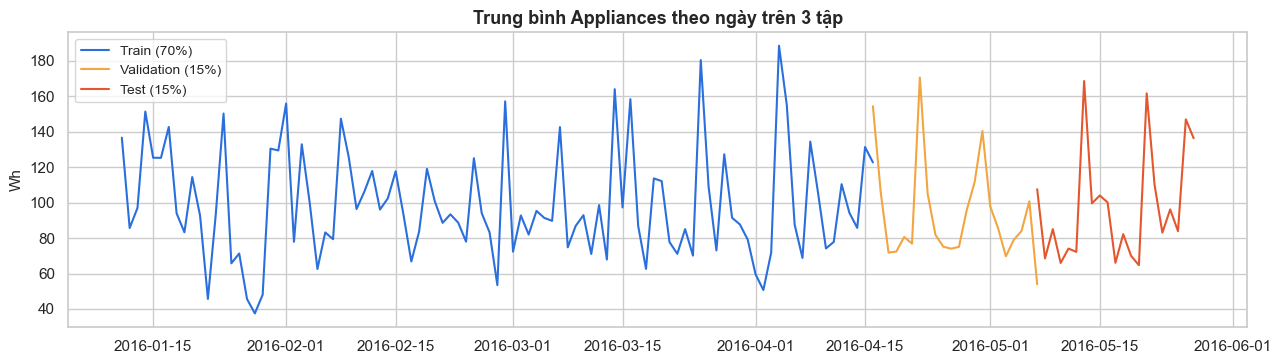

In [3]:
fig, ax = plt.subplots(figsize=(13, 3.8))
for part, name, color in [(train, "Train (70%)", "#2a6fdb"), (val, "Validation (15%)", "#f2a541"),
                          (test, "Test (15%)", "#e4572e")]:
    daily = part.set_index("date")[TARGET].resample("D").mean()
    ax.plot(daily.index, daily.values, color=color, label=name)
ax.set_title("Trung bình Appliances theo ngày trên 3 tập")
ax.set_ylabel("Wh")
ax.legend()
fig.tight_layout()
save_fig(fig, "03_time_split")
plt.show()

**Nhận xét:**
- Ba tập nối tiếp nhau theo thời gian, không chồng lấn: train 11/01 → 16/04, validation 16/04 → 07/05,
  test 07/05 → 27/05.
- Trung bình biến mục tiêu ba tập gần nhau (98,8 / 93,4 / 96,9 Wh), trung vị đều 60 Wh → không lệch phân phối
  lớn giữa các tập.
- **Vai trò:** train → huấn luyện, cross-validation, tinh chỉnh; validation → so sánh và **chọn** mô hình;
  test → đánh giá cuối cùng, **chỉ dùng một lần** ở notebook đánh giá.
- **Lưu ý:** tập validation và test rơi vào cuối mùa xuân (ấm hơn, ngày dài hơn) trong khi train phần lớn là mùa
  đông → mô hình phải tổng quát hóa sang điều kiện thời tiết chưa thấy nhiều. Đây là thử thách thật của bài toán.

## 2. Thí nghiệm: chia ngẫu nhiên và chia theo thời gian
Huấn luyện **cùng một mô hình** (Random Forest mặc định, 100 cây) theo hai cách chia:
- **Ngẫu nhiên** 75/25 (như nhiều bài làm và bài báo gốc).
- **Theo thời gian** (train → validation).

In [4]:
X_all, y_all = make_xy(df)
X_a, X_b, y_a, y_b = train_test_split(X_all, y_all, test_size=0.25, random_state=RANDOM_STATE)
rf = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_a, y_a)
random_split = regression_metrics(y_b, rf.predict(X_b))

X_tr, y_tr = make_xy(train)
X_va, y_va = make_xy(val)
rf_t = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_t.fit(X_tr, y_tr)
time_split_res = regression_metrics(y_va, rf_t.predict(X_va))

pd.DataFrame({"Chia ngẫu nhiên": random_split, "Chia theo thời gian": time_split_res}).T.round(3)

,MAE,RMSE,R2,MAPE_%
Chia ngẫu nhiên,31.653,66.279,0.558,31.729
Chia theo thời gian,69.056,103.464,-0.258,86.876


**Kết quả rất khác nhau:** chia ngẫu nhiên cho R² ≈ 0,56 (gần đúng con số 0,57 của bài báo gốc), nhưng chia
theo thời gian thì R² **âm** (≈ −0,26) – mô hình còn kém hơn cả việc đoán trung bình.

**Vì sao?** Dữ liệu đo mỗi 10 phút nên hai mẫu liền kề gần như giống hệt nhau (nhiệt độ, độ ẩm thay đổi rất
chậm). Khi chia ngẫu nhiên, với gần như mọi mẫu trong tập test, mẫu 10 phút trước và 10 phút sau đều nằm trong
tập train → Random Forest chỉ cần "tra lại" hàng xóm gần nhất. Đây là **rò rỉ dữ liệu (data leakage)**: điểm cao
nhưng không phản ánh khả năng dự đoán thật cho tương lai.

In [5]:
# Minh chứng: với mỗi mẫu test (chia ngẫu nhiên), có bao nhiêu % có mẫu liền trước hoặc liền sau trong train?
idx_train = set(X_a.index)
neighbor = np.mean([(i - 1 in idx_train) or (i + 1 in idx_train) for i in X_b.index])
print(f"{neighbor:.1%} mẫu test có hàng xóm 10 phút nằm trong train")

93.6% mẫu test có hàng xóm 10 phút nằm trong train


**Quyết định của nhóm:** dùng **chia theo thời gian** cho toàn bộ thực nghiệm, và `TimeSeriesSplit` cho
cross-validation. Kết quả sẽ thấp hơn bài báo gốc nhưng **trung thực** với tình huống sử dụng thật: học từ quá
khứ để dự đoán tương lai. Đây cũng là câu trả lời một phần cho **RQ1**.

## 3. Pipeline tiền xử lý
Hàm `make_pipeline` trong `src/preprocessing.py` ghép tiền xử lý và mô hình thành một `Pipeline`:
- Mô hình tuyến tính / MLP: `StandardScaler` cho biến số + `OneHotEncoder` cho `day_of_week`.
- Mô hình cây: giữ nguyên dữ liệu (`passthrough`).

In [6]:
from src.preprocessing import build_preprocessor

cols = list(X_tr.columns)
prep = build_preprocessor(cols, kind="linear")
prep.fit(X_tr)
print("Số đặc trưng đầu vào :", len(cols))
print("Số cột sau tiền xử lý:", len(prep.get_feature_names_out()), "(day_of_week → 7 cột one-hot)")

Số đặc trưng đầu vào : 31
Số cột sau tiền xử lý: 37 (day_of_week → 7 cột one-hot)


In [7]:
Z_tr = pd.DataFrame(prep.transform(X_tr), columns=prep.get_feature_names_out())
Z_va = pd.DataFrame(prep.transform(X_va), columns=prep.get_feature_names_out())
check = pd.DataFrame({
    "TB train": Z_tr[["T1", "RH_1", "T_out", "Press_mm_hg"]].mean(),
    "ĐLC train": Z_tr[["T1", "RH_1", "T_out", "Press_mm_hg"]].std(),
    "TB validation": Z_va[["T1", "RH_1", "T_out", "Press_mm_hg"]].mean(),
})
check.round(3)

,TB train,ĐLC train,TB validation
T1,0.0,1.0,0.760
RH_1,-0.0,1.0,-0.936
T_out,-0.0,1.0,0.603
Press_mm_hg,0.0,1.0,0.461


**Kiểm soát rò rỉ dữ liệu:** scaler chỉ được `fit` trên **train** → sau chuẩn hóa, train có trung bình 0 và độ
lệch chuẩn 1, còn validation thì **không** (vd. `T_out` validation có trung bình dương vì tháng 4–5 ấm hơn mùa
đông). Nếu fit scaler trên toàn bộ dữ liệu, thông tin về nhiệt độ của tương lai sẽ "lọt" vào lúc huấn luyện.

Khi cross-validation, tiền xử lý nằm **trong** Pipeline nên được fit lại trên phần train của từng fold.

## 4. Tổng kết chiến lược thực nghiệm

| Thành phần | Lựa chọn | Lý do |
|---|---|---|
| Chia dữ liệu | Theo thời gian 70/15/15 | Tránh rò rỉ giữa các mẫu liền kề (mục 2) |
| Cross-validation | `TimeSeriesSplit(n_splits=5)` trên train | Fold validation luôn nằm sau dữ liệu huấn luyện |
| Chọn mô hình | Theo RMSE trên **validation** (và CV) | Test giữ riêng, chỉ dùng **một lần** cuối cùng |
| Độ đo | RMSE (chính), MAE, R², MAPE | RMSE so sánh được với bài báo; MAE ít nhạy ngoại lệ |
| Baseline | Dự đoán trung bình; trung bình theo giờ | Mốc tối thiểu mô hình phải vượt |
| Tiền xử lý | Chuẩn hóa + one-hot (tuyến tính, MLP); không xử lý (cây) | Mục 3, `preprocessing.py` |
| Bộ đặc trưng chính | `full` (31 đặc trưng, gồm `rv1` đối chứng) | `features.py` |
| Tái lập | `random_state = 42` cố định | Chạy lại cho cùng kết quả |